## Helper Functions

### Helper function to visualize the images with their respective RGB 3D distribution


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objs as go

def visualize_images_and_distributions(source, target, result, subsample_factor=10, interactive_plot=False):
    """
    Display source, target, and result images (top row)
    and their RGB color distributions (bottom row).

    Parameters
    ----------
    source, target, result : np.ndarray
        Input images in RGB format (values in [0, 1] or [0, 255]).
    subsample_factor : int, optional
        Factor by which to subsample pixels for faster visualization (default=10).
    interactive_plot : bool, optional
        If True, shows Plotly 3D interactive color distributions (separate windows).
        If False, shows them in static Matplotlib 3D plots.
    """

    def preprocess_image(img):
        """Ensure image is float in [0,1] and flattened."""
        if img.dtype == np.uint8:
            img = img / 255.0
        X = img.reshape((-1, 3))
        if subsample_factor > 1:
            nb = int(X.shape[0] / subsample_factor)
            r = np.random.RandomState(42)
            idx = r.randint(X.shape[0], size=(nb,))
            X = X[idx, :]
        return X

    # Prepare data
    imgs = {
        "Source": (source, preprocess_image(source)),
        "Target": (target, preprocess_image(target)),
        "Result": (result, preprocess_image(result))
    }

    # === Create a 2x3 Matplotlib figure ===
    fig = plt.figure(figsize=(15, 10), constrained_layout=True)

    # --- Top row: original images ---
    for i, (title, (img, _)) in enumerate(imgs.items(), start=1):
        ax = fig.add_subplot(2, 3, i)
        ax.imshow(img)
        ax.set_title(title)
        ax.axis("off")

    # --- Bottom row: 3D RGB distributions ---
    for i, (title, (_, Xs)) in enumerate(imgs.items(), start=1):
        ax = fig.add_subplot(2, 3, i + 3, projection='3d')
        ax.scatter(Xs[:, 0], Xs[:, 1], Xs[:, 2], c=Xs, s=8)
        ax.set_xlabel("R")
        ax.set_ylabel("G")
        ax.set_zlabel("B")
        ax.set_title(f"{title} RGB Distribution")
        ax.view_init(elev=20, azim=135)

    fig.suptitle("Image Comparison and 3D RGB Distributions", fontsize=15, y=0.98)
    plt.show()

    # === Optional interactive version ===
    if interactive_plot:
        for title, (_, Xs) in imgs.items():
            fig_plotly = go.Figure(data=[go.Scatter3d(
                x=Xs[:, 0],
                y=Xs[:, 1],
                z=Xs[:, 2],
                mode='markers',
                marker=dict(
                    size=2,
                    color=['rgb({},{},{})'.format(int(r*255), int(g*255), int(b*255))
                           for r, g, b in Xs]
                )
            )])
            fig_plotly.update_layout(
                scene=dict(xaxis_title='R', yaxis_title='G', zaxis_title='B'),
                width=700,
                height=600,
                title=f"3D RGB Distribution ({title})"
            )
            fig_plotly.show()

## SWP method

In [ ]:
import torch
import torch.nn.functional as F
from skimage import color
from tqdm import trange
import matplotlib.pyplot as plt


# ==============================
# Utility functions
# ==============================

def random_unit_vector(d=3, device='cuda'):
    """Sample a random unit vector θ ∈ S^{d−1} on GPU."""
    v = torch.randn(d, device=device)
    v = v / v.norm()
    return v


# ==============================
# Core sliced projection step
# ==============================

def sliced_projection_step(f, g, theta):
    """
    Perform one sliced Wasserstein projection step along a single direction θ.
    Returns both the displacement vectors and the sliced Wasserstein distance along θ.
    """
    N, d = f.shape
    M = g.shape[0]

    f_proj = f @ theta
    g_proj = g @ theta

    f_sorted, idx_f = torch.sort(f_proj)
    g_sorted, _ = torch.sort(g_proj)

    # Normalized quantiles
    p_f = torch.linspace(0, 1, N, device=f.device)
    p_g = torch.linspace(0, 1, M, device=f.device)

    # Interpolation
    if hasattr(torch, "interp"):
        g_interp = torch.interp(p_f, p_g, g_sorted)
    else:
        idx = torch.searchsorted(p_g, p_f, right=True).clamp(1, M - 1)
        x0, x1 = p_g[idx - 1], p_g[idx]
        y0, y1 = g_sorted[idx - 1], g_sorted[idx]
        t = (p_f - x0) / (x1 - x0)
        g_interp = y0 + t * (y1 - y0)


    f_proj_matched = torch.zeros_like(f_proj)
    f_proj_matched[idx_f] = g_interp

    delta = (f_proj_matched - f_proj).unsqueeze(1) * theta.unsqueeze(0)
    swd_theta = torch.mean((f_proj - f_proj_matched) ** 2)
    return delta, swd_theta


# ============================
# SWP
# ============================
def sliced_wasserstein_projection(
    source,
    target,
    n_iter=500,
    n_dirs=10,
    tau=5.4,
    #--- dual-epsilon convergence params ---
    epsilon_short=1e-4, # for |SWD_t - SWD_{t-1}|
    epsilon_long=5e-4, # for |SWD_t - SWD_{t-k_gap}|
    k_gap=5, # look-back gap for long horizon
    patience_short=3, # how many consecutive passes for short diff
    patience_long=2, # how many passes for long diff
    min_iters=10, # don't stop too early device='cuda
    device='cuda'
):
    """
    SWP operating **purely in RGB space** with values in [0,255].
    No Lab conversion, no normalization.

    f and g are N×3 matrices in RGB space.
    """

    # ------------------------------------------------------------
    # Prepare data in RGB (float32, but stay in 0..255 range)
    # ------------------------------------------------------------
    source = source.astype('float32')
    target = target.astype('float32')

    H, W, C = source.shape
    f = torch.tensor(source.reshape(-1, C), device=device)
    g = torch.tensor(target.reshape(-1, C), device=device)

    swd_curve = []
    pass_short = 0
    pass_long  = 0

    # ------------------------------------------------------------
    # SWP iterations
    # ------------------------------------------------------------
    for it in trange(n_iter, desc="SWP iterations"):
        total_delta = torch.zeros_like(f)
        swd_iter_vals = []

        # ----- random directions -----
        for _ in range(n_dirs):
            theta = random_unit_vector(C, device=device)   # in R^3
            delta, swd_theta = sliced_projection_step(f, g, theta)
            total_delta += delta
            swd_iter_vals.append(swd_theta)

        swd_val = torch.mean(torch.stack(swd_iter_vals)).item()
        swd_curve.append(swd_val)

        # ----- Gradient descent update -----
        f = f + tau * total_delta / n_dirs

        # ------------------------------------------------------------
        # Dual-ε convergence check
        # ------------------------------------------------------------
        if it >= 1:
            diff_short = abs(swd_curve[-1] - swd_curve[-2])
            if diff_short < epsilon_short:
                pass_short += 1
            else:
                pass_short = 0

        if it >= k_gap:
            diff_long = abs(swd_curve[-1] - swd_curve[-1-k_gap])
            if diff_long < epsilon_long:
                pass_long += 1
            else:
                pass_long = 0

        if (it >= min_iters and
            pass_short >= patience_short and
            pass_long >= patience_long):
            print(f"\n Converged at iteration {it} "
                  f"(Δ1<{epsilon_short}, Δ{ k_gap }<{epsilon_long})")
            break

    # ------------------------------------------------------------
    # Return RGB image (clipped to valid range)
    # ------------------------------------------------------------
    f_img = f.reshape(H, W, C).detach().cpu().numpy()
    f_img = np.clip(f_img, 0, 255)
    out = (f_img + 0.5).astype('uint8')


    return out, swd_curve



# ==============================
# Plot helpers
# ==============================

def plot_swd_curves(swd_curves, labels=None):
    """Plot one or more SWD curves."""

    # Case 1: a single curve -> list of floats
    if isinstance(swd_curves, (list, tuple)) and \
       len(swd_curves) > 0 and isinstance(swd_curves[0], (int, float)):
        swd_curves = [swd_curves]

    if labels is None:
        labels = [f"Curve {i+1}" for i in range(len(swd_curves))]

    plt.figure(figsize=(7,5))

    for curve, label in zip(swd_curves, labels):
        plt.plot(curve, linewidth=1.8, label=label)

    plt.title("Sliced Wasserstein Distance vs Iteration")
    plt.xlabel("Iteration")
    plt.ylabel("Approx. SWD")
    if len(swd_curves) > 1:
        plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


def plot_tail_subplots(all_results, tail_len=20):
    """
    Plot the last `tail_len` SWD values for each curve.
    all_results can be:
      - list of (result_img, swd_curve)
      - dict of {anything: (result_img, swd_curve)}
    τ values or keys are ignored.
    """

    if isinstance(all_results, dict):
        curves = [curve for (_, curve) in all_results.values()]
    else:
        curves = [curve for (_, curve) in all_results]

    n = len(curves)
    plt.figure(figsize=(12, 2.5 * n))

    for i, curve in enumerate(curves):
        tail = curve[-tail_len:] if len(curve) >= tail_len else curve
        x = range(len(curve) - len(tail), len(curve))
        plt.subplot(n, 1, i + 1)
        plt.plot(x, tail, marker='o')
        plt.title(f"Curve {i+1}")
        plt.ylabel("SWD")
        plt.grid(alpha=0.3)

    plt.xlabel("Iteration")
    plt.tight_layout()
    plt.show()



# ==============================
# Tau sweep
# ==============================
def tau_sweep_swp(
    source,
    target,
    taus=[0.1, 0.2, 0.3, 0.4, 0.5],
    n_iter=200,
    n_dirs=10,
    device="cuda",
    epsilon_short=1e-4,
    epsilon_long=5e-4,
    k_gap=5,
    patience_short=3,
    patience_long=2,
    min_iters=10
    ):
    """
    Brute-force test of different τ values for SWP.
    For each τ:
      - runs SWP,
      - shows Source–Target–Result images,
      - plots the SWD curve,
      - stores both the result image and SWD curve.
    Finally, redraws all SWD curves together on one plot.
    """
    all_results = {}
    print(f"Running τ-sweep on {len(taus)} values...")

    for tau in taus:
        print(f"\n=== Testing τ = {tau} ===")

        # --- Run SWP for this τ ---
        result_img, swd_curve = sliced_wasserstein_projection(
            source,
            target,
            n_iter=n_iter,
            n_dirs=n_dirs,
            tau=tau,
            epsilon_short=epsilon_short,
            epsilon_long=epsilon_long,
            k_gap=k_gap,
            patience_short=patience_short,
            patience_long=patience_long,
            min_iters=min_iters,
            device=device
        )

        all_results[tau] = (result_img, swd_curve)

    # --- Print summary table ---
    print("\nSummary (last SWD and total iterations):")
    for tau, (_, curve) in all_results.items():
        print(f"τ={tau:<6}  →  Final SWD={curve[-1]:.6f}  after {len(curve)} iterations")

    # --- Combined SWD curves for comparison ---
    plt.figure(figsize=(8, 5))
    for tau, (_, curve) in sorted(all_results.items()):
        plt.plot(curve, linewidth=2.0, label=f"τ = {tau}")
    plt.title("SWD Convergence Comparison for All τ Values")
    plt.xlabel("Iteration")
    plt.ylabel("Approx. Sliced Wasserstein Distance")
    plt.legend(title="Step size τ", fontsize=9)
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig("tau_sweep.pdf", format="pdf", dpi=300, bbox_inches='tight')

    plt.show()


    return all_results

### Testing

In [ ]:
from skimage import io
source = io.imread("ColabFiles/source.jpg")
target = io.imread("ColabFiles/target.jpg")

SWP iterations:  40%|████      | 101/250 [01:06<01:38,  1.52it/s]


 Converged at iteration 101 (Δ1<0.0001, Δ5<0.0005)


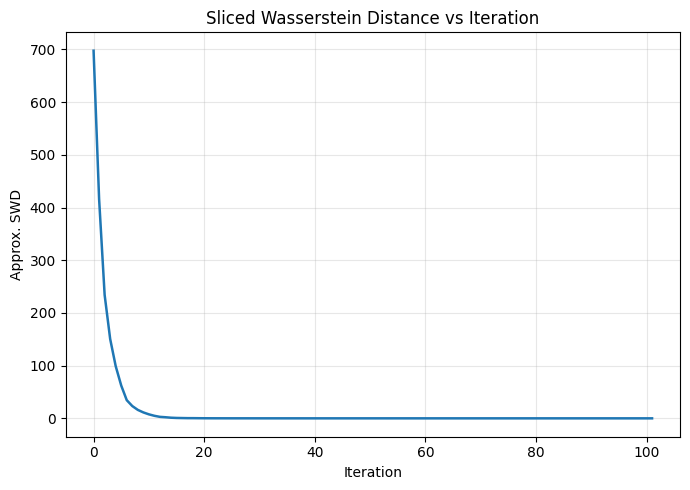

In [ ]:
result, curve = sliced_wasserstein_projection(
    source,
    target,
    n_iter=250,
    n_dirs=250,
    tau=5.4,
    epsilon_short=1e-4,
    epsilon_long=5e-4,
    k_gap=5,
    patience_short=3,
    patience_long=2,
    min_iters=10,
    device='cuda'
)

plot_swd_curves(curve)



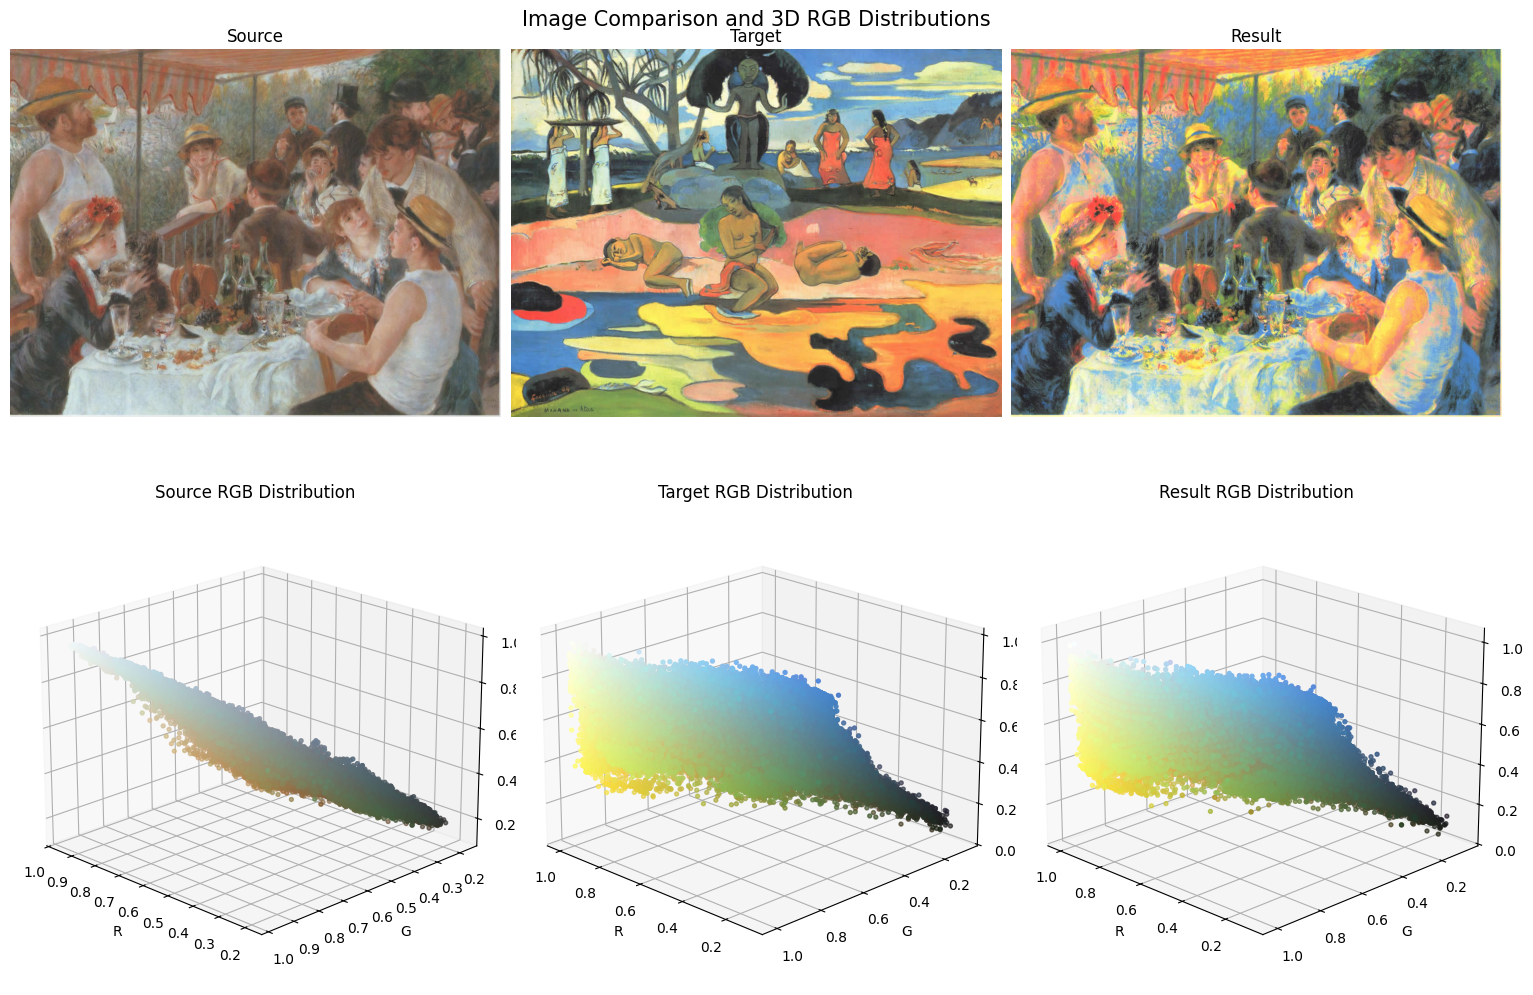

In [ ]:
visualize_images_and_distributions(source, target, result)

Running τ-sweep on 7 values...

=== Testing τ = 0.1 ===


SWP iterations: 100%|██████████| 250/250 [02:43<00:00,  1.53it/s]



=== Testing τ = 0.5 ===


SWP iterations: 100%|██████████| 250/250 [02:42<00:00,  1.53it/s]



=== Testing τ = 1 ===


SWP iterations: 100%|██████████| 250/250 [02:43<00:00,  1.53it/s]


... (5 outputs left out)

SWP iterations:  44%|████▎     | 109/250 [01:11<01:32,  1.52it/s]



 Converged at iteration 109 (Δ1<0.0001, Δ5<0.0005)

=== Testing τ = 5.8 ===


SWP iterations:  46%|████▌     | 115/250 [01:15<01:28,  1.52it/s]


 Converged at iteration 115 (Δ1<0.0001, Δ5<0.0005)

Summary (last SWD and total iterations):
τ=0.1     →  Final SWD=2.197324  after 250 iterations
τ=0.5     →  Final SWD=0.046662  after 250 iterations
τ=1       →  Final SWD=0.010766  after 250 iterations
τ=3       →  Final SWD=0.007231  after 105 iterations
τ=5       →  Final SWD=0.002538  after 118 iterations
τ=5.4     →  Final SWD=0.002323  after 110 iterations
τ=5.8     →  Final SWD=0.002061  after 116 iterations


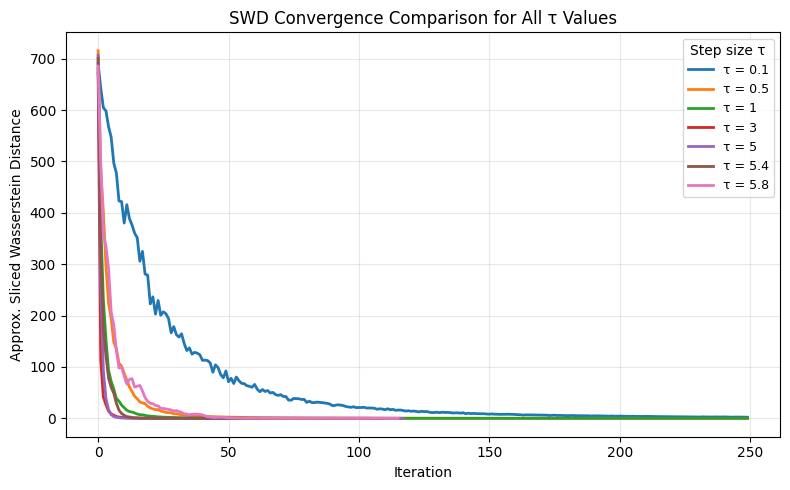

τ=0.1     →  Final SWD=2.197324  after 250 iterations
τ=0.5     →  Final SWD=0.046662  after 250 iterations
τ=1       →  Final SWD=0.010766  after 250 iterations
τ=3       →  Final SWD=0.007231  after 105 iterations
τ=5       →  Final SWD=0.002538  after 118 iterations
τ=5.4     →  Final SWD=0.002323  after 110 iterations
τ=5.8     →  Final SWD=0.002061  after 116 iterations


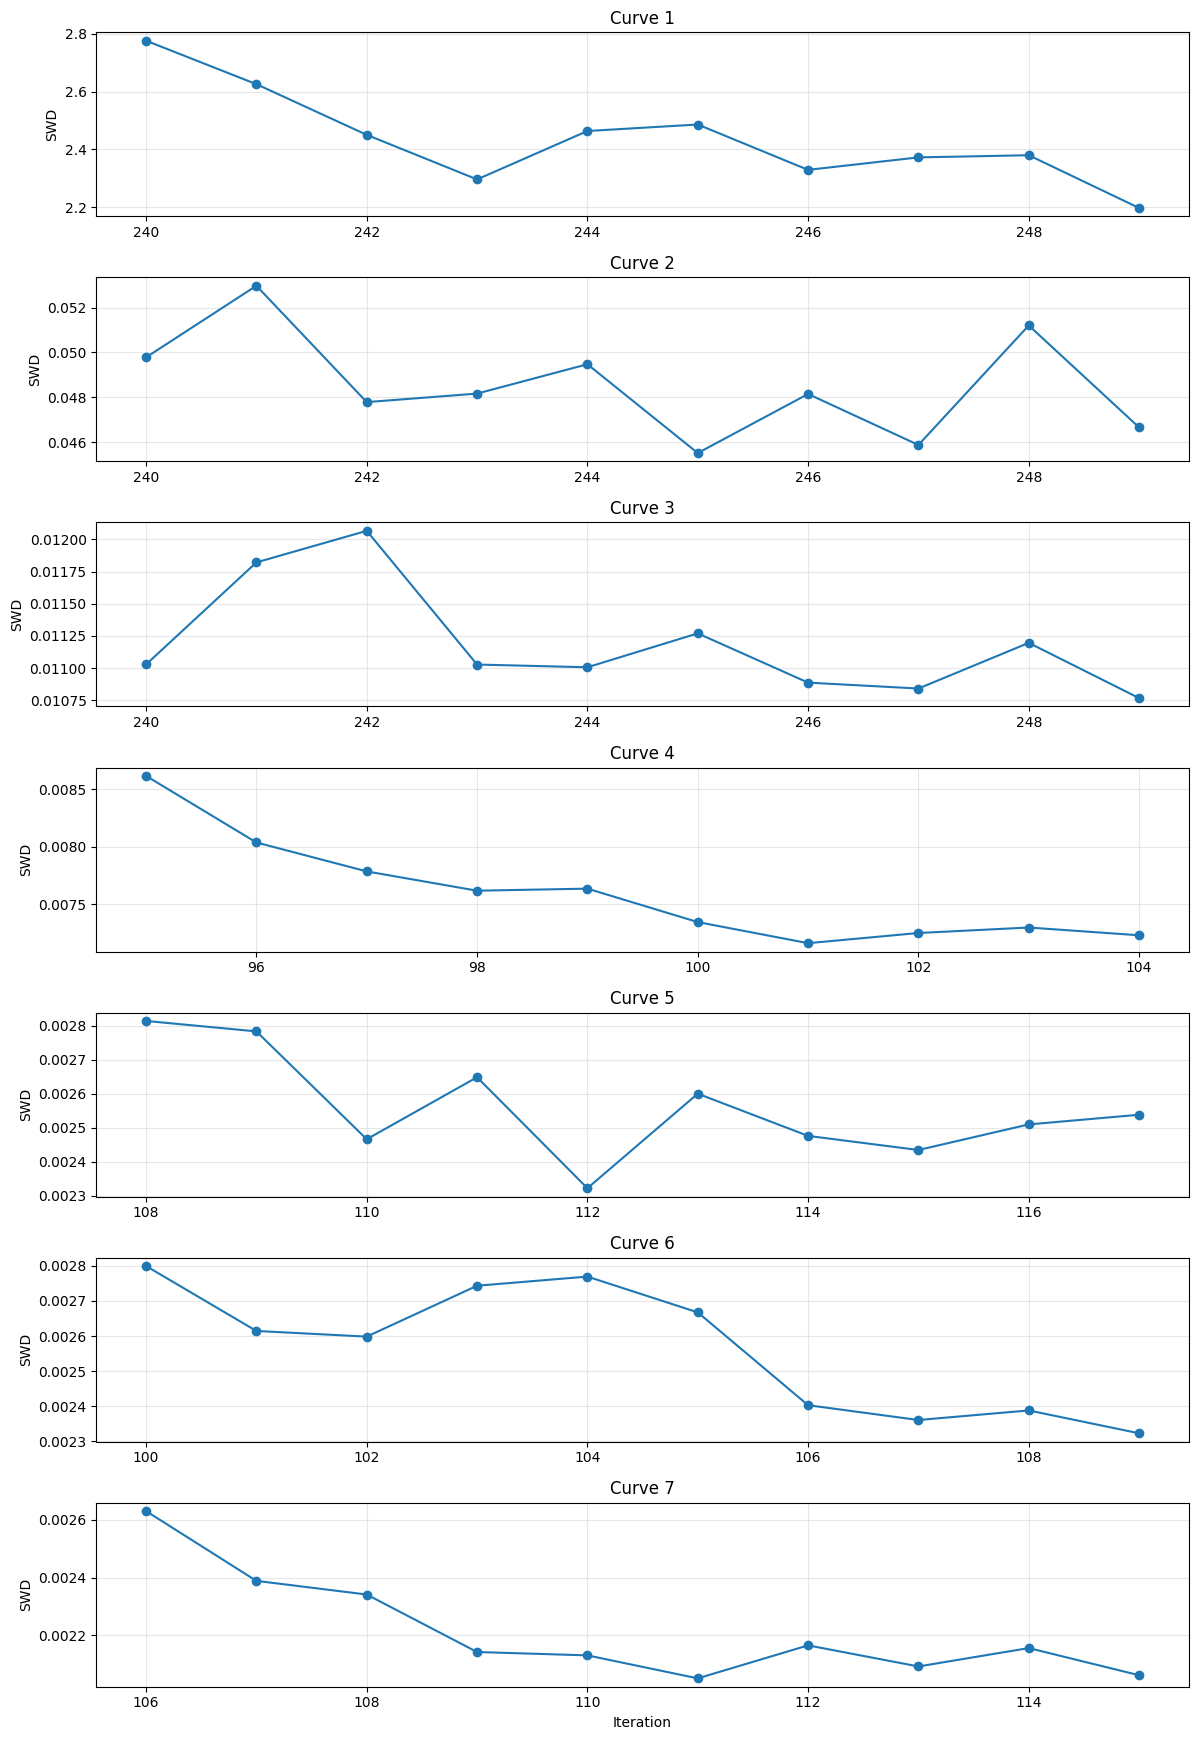

In [ ]:
taus = [0.1, 0.5, 1, 3, 5, 5.4, 5.8]

results = tau_sweep_swp(
    source,
    target,
    taus=taus,
    n_iter=250,
    n_dirs=250,
    device="cuda",
    epsilon_short=1e-4,
    epsilon_long=5e-4,
    k_gap=5,
    patience_short=3,
    patience_long=2,
    min_iters=10
)


for tau, (_, curve) in results.items():
    print(f"τ={tau:<6}  →  Final SWD={curve[-1]:.6f}  after {len(curve)} iterations")

plot_tail_subplots(results, tail_len=10)